# Cancelaciones hoteleras: clasificación y priorización
**Evolve Academy · Máster en Data Science & IA · Entrega académica, 26/10/2026**

Las cancelaciones dificultan planificar inventario e ingresos. El objetivo es estimar riesgo de cancelación (`is_canceled=1`) y estudiar una priorización de seguimiento humano con capacidad limitada. Las asociaciones no demuestran que contactar evite una cancelación ni permiten cuantificar ahorro.

Este notebook **reconstruye el proceso desde el CSV**, entrena modelos y calcula métricas nuevas. No carga modelos ni predicciones históricas. Las cifras históricas se incluyen como referencias identificadas y no se sobrescriben. La optimización complementaria se realiza **después de la selección histórica**, exclusivamente en train v3, y no cambia el modelo final de referencia.

**Instante y alcance:** idealmente se predeciría al reservar, pero faltan snapshots iniciales, creación observada y cierre de PMS acreditado. Por ello utilizamos cohortes retrospectivas de llegada (v3), no validación prospectiva. El EDA histórico vio todo el archivo y 3.037 filas del test v3 ya participaron en desarrollo v2. Una reconstrucción reproducible no elimina esa exposición.

Ejecutar desde esta carpeta con `hotel_bookings.csv` junto al notebook. Dependencias e instalación en README. No hay importaciones del proyecto histórico, descargas ni escrituras de artefactos durante la ejecución.

In [1]:
from pathlib import Path
import hashlib, importlib.metadata, json, platform, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.special import expit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                            recall_score, f1_score, confusion_matrix, brier_score_loss,
                            roc_curve, precision_recall_curve)
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBClassifier
with warnings.catch_warnings():
    # Aviso opcional de widgets: no afecta al cálculo ni requiere ipywidgets.
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    import shap

INICIO = time.perf_counter()
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
VERSIONES = {p: importlib.metadata.version(p) for p in
             ['numpy','pandas','scipy','matplotlib','seaborn','scikit-learn','xgboost','shap']}
display(pd.Series({'python': platform.python_version(), **VERSIONES}, name='versión observada').to_frame())

,versión observada
python,3.14.5
numpy,2.4.6
pandas,3.0.3
scipy,1.18.1
matplotlib,3.11.0
seaborn,0.13.2
scikit-learn,1.9.0
xgboost,3.4.1
shap,0.54.1


## 1. Dataset y validación
Fuente científica: António, Almeida y Nunes (2019), *Hotel booking demand datasets*, Data in Brief 22, 41–49, DOI [10.1016/j.dib.2018.11.126](https://doi.org/10.1016/j.dib.2018.11.126). El archivo combinado contiene dos hoteles portugueses, julio de 2015 a agosto de 2017. El hash identifica nuestra copia, no certifica la cadena de descarga o licencia.

Se incluye el CSV original recuperado. La comparación con el Excel del profesor encontró **230 celdas ADR convertidas a fechas** (por ejemplo, 24,8 pasa a un serial 46258). El resto coincide tras normalizar tipos y ordenar columnas por nombre. No sustituimos ni corregimos silenciosamente el Excel.

In [2]:
DATA_PATH = Path('hotel_bookings.csv')
if not DATA_PATH.is_file():
    raise FileNotFoundError('Ejecute desde la carpeta que contiene hotel_bookings.csv.')
CSV_SHA = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert CSV_SHA == '7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06', 'CSV distinto del original'
raw = pd.read_csv(DATA_PATH)
assert raw.shape == (119390, 32)
assert raw.is_canceled.notna().all() and raw.is_canceled.isin([0,1]).all()
MONTHS = {m: i+1 for i,m in enumerate(['January','February','March','April','May','June',
                                    'July','August','September','October','November','December'])}
arrival = pd.to_datetime(dict(year=raw.arrival_date_year,
                             month=raw.arrival_date_month.map(MONTHS), day=raw.arrival_date_day_of_month))
row_id = pd.Series(np.arange(len(raw)), index=raw.index, name='meta_row_id')
duplicate_group = pd.util.hash_pandas_object(raw, index=False)
display(pd.DataFrame({'tipo':raw.dtypes.astype(str), 'ausentes':raw.isna().sum()}))
display(pd.Series({'filas':len(raw), 'canceladas':int(raw.is_canceled.sum()),
                   'tasa_cancelación':raw.is_canceled.mean(),
                   'duplicados_adicionales':int(raw.duplicated().sum()),
                   'ADR_negativo':int(raw.adr.lt(0).sum()),
                   'ADR_máximo':raw.adr.max(), 'llegada_inicial':str(arrival.min().date()),
                   'llegada_final':str(arrival.max().date())}, name='calidad').to_frame())

,tipo,ausentes
hotel,str,0
is_canceled,int64,0
lead_time,int64,0
arrival_date_year,int64,0
arrival_date_month,str,0
arrival_date_week_number,int64,0
arrival_date_day_of_month,int64,0
stays_in_weekend_nights,int64,0
stays_in_week_nights,int64,0
adults,int64,0


,calidad
filas,119390
canceladas,44224
tasa_cancelación,0.370416
duplicados_adicionales,31994
ADR_negativo,1
ADR_máximo,5400.0
llegada_inicial,2015-07-01
llegada_final,2017-08-31


## 2. EDA con decisiones de negocio
Cada tasa utiliza las reservas del propio grupo como denominador. El EDA describe **todo el archivo**, no el rendimiento de test. Se conservan duplicados, ADR negativo/extremo y casos anómalos para no inventar correcciones. No hay ID real de cliente o reserva que permita adjudicar repeticiones a errores.

### Hotel y mes de llegada

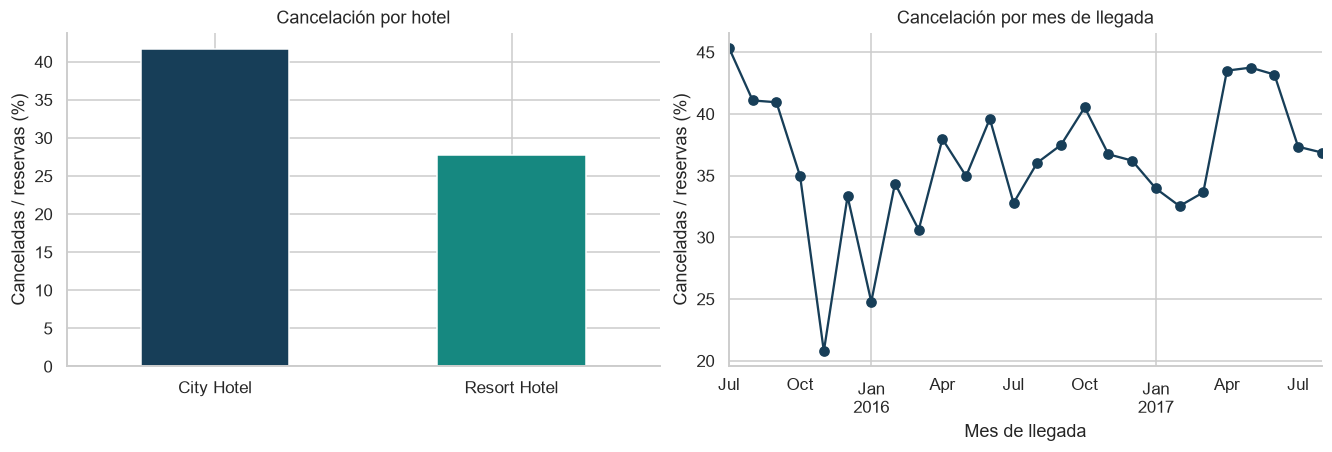

,reservas,canceladas,tasa
hotel,,,
City Hotel,79330,33102,0.417270
Resort Hotel,40060,11122,0.277634


,reservas,canceladas,tasa
2015-07,2776,1259,0.453530
2015-08,3889,1598,0.410903
2015-09,5114,2094,0.409464
2015-10,4957,1732,0.349405
2015-11,2340,486,0.207692
2015-12,2920,973,0.333219
2016-01,2248,557,0.247776
2016-02,3891,1337,0.343613
2016-03,4824,1477,0.306177
2016-04,5428,2061,0.379698


**Hotel:** City registra 41.73% frente a 27.76% de Resort. **Acción:** dimensionar por hotel la revisión humana y medir su cobertura; no trasladar una cuota conjunta sin revisar capacidad local. **Mes:** planificar revisiones y previsión de ocupación por cohorte mensual. Solo 2016 tiene doce meses: no comparar totales anuales sin ajustar cobertura ni asumir estacionalidad estable.

In [3]:
def tabla_tasas(groups):
    return raw.groupby(groups, observed=True, dropna=False).is_canceled.agg(
        reservas='size', canceladas='sum', tasa='mean')

hotel_eda = tabla_tasas('hotel')
mes_eda = tabla_tasas(arrival.dt.to_period('M'))
fig, ax = plt.subplots(1,2,figsize=(12,4), layout='constrained')
hotel_eda.tasa.mul(100).plot.bar(ax=ax[0], color=['#173e58','#168880'], rot=0)
ax[0].set(title='Cancelación por hotel', ylabel='Canceladas / reservas (%)', xlabel='')
mes_eda.tasa.mul(100).plot(ax=ax[1], marker='o', color='#173e58')
ax[1].set(title='Cancelación por mes de llegada', ylabel='Canceladas / reservas (%)', xlabel='Mes de llegada')
plt.show(); plt.close(fig)
display(hotel_eda); display(mes_eda)
display(Markdown(f"**Hotel:** City registra {hotel_eda.loc['City Hotel','tasa']:.2%} frente a "
 f"{hotel_eda.loc['Resort Hotel','tasa']:.2%} de Resort. **Acción:** dimensionar por hotel la revisión humana y "
 "medir su cobertura; no trasladar una cuota conjunta sin revisar capacidad local. **Mes:** planificar revisiones "
 "y previsión de ocupación por cohorte mensual. Solo 2016 tiene doce meses: no comparar totales anuales sin ajustar cobertura ni asumir estacionalidad estable."))

### Canal, antelación y ADR

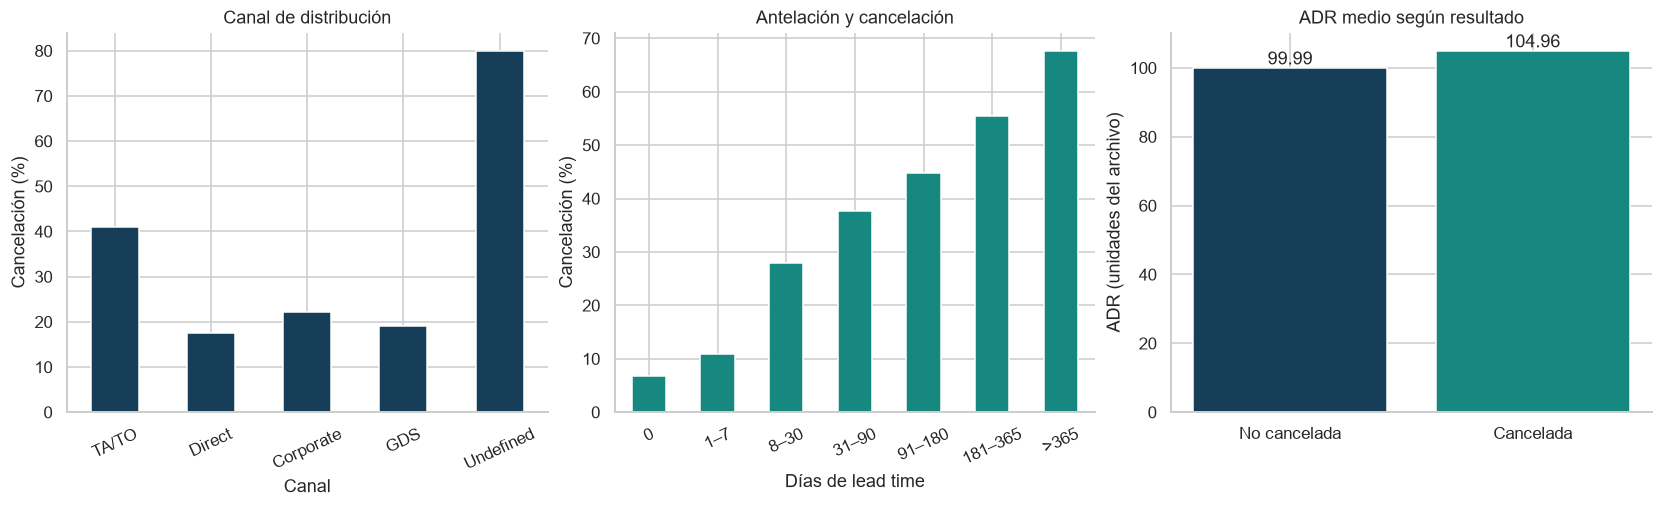

,reservas,canceladas,tasa
distribution_channel,,,
TA/TO,97870,40152,0.410259
Direct,14645,2557,0.174599
Corporate,6677,1474,0.220758
GDS,193,37,0.191710
Undefined,5,4,0.800000


,reservas,canceladas,tasa
lead_time,,,
0,6345,430,0.067770
1–7,13401,1472,0.109843
8–30,18960,5283,0.278639
31–90,29553,11141,0.376984
91–180,26439,11821,0.447105
181–365,21544,11947,0.554540
>365,3148,2130,0.676620


,reservas,media,mediana
is_canceled,,,
0,75166,99.987693,92.5
1,44224,104.964333,96.2


**Canal:** TA/TO tiene 41.03% de cancelación. **Acción:** coordinar seguimiento con agencias según volumen y riesgo, sin penalizar canales automáticamente. **Antelación:** las tasas son 6.78% a cero días y 67.66% por encima de 365. **Acción:** probar recordatorios en reservas anticipadas con un piloto controlado. **ADR:** medias 99.99 y 104.96. **Acción:** revisar riesgo de ingresos por rangos tarifarios y hotel; no subir precios ni endurecer depósitos por esta asociación. Las medias incluyen un negativo y el extremo de 5.400; no se interpreta una diferencia ajustada ni causal.

In [4]:
canal_eda = tabla_tasas('distribution_channel').sort_values('reservas',ascending=False)
bandas = pd.cut(raw.lead_time, [-np.inf,0,7,30,90,180,365,np.inf],
                labels=['0','1–7','8–30','31–90','91–180','181–365','>365'])
lead_eda = tabla_tasas(bandas)
adr_eda = raw.groupby('is_canceled').adr.agg(reservas='size',media='mean',mediana='median')
fig, ax = plt.subplots(1,3,figsize=(15,4.5), layout='constrained')
canal_eda.tasa.mul(100).plot.bar(ax=ax[0],color='#173e58',rot=25)
ax[0].set(title='Canal de distribución',ylabel='Cancelación (%)',xlabel='Canal')
lead_eda.tasa.mul(100).plot.bar(ax=ax[1],color='#168880',rot=25)
ax[1].set(title='Antelación y cancelación',ylabel='Cancelación (%)',xlabel='Días de lead time')
ax[2].bar(['No cancelada','Cancelada'],adr_eda.media,color=['#173e58','#168880'])
ax[2].set(title='ADR medio según resultado',ylabel='ADR (unidades del archivo)')
for i,value in enumerate(adr_eda.media):ax[2].text(i,value+1,f'{value:.2f}',ha='center')
plt.show(); plt.close(fig)
display(canal_eda);display(lead_eda);display(adr_eda)
display(Markdown(f"**Canal:** TA/TO tiene {canal_eda.loc['TA/TO','tasa']:.2%} de cancelación. "
 "**Acción:** coordinar seguimiento con agencias según volumen y riesgo, sin penalizar canales automáticamente. "
 f"**Antelación:** las tasas son {lead_eda.iloc[0].tasa:.2%} a cero días y {lead_eda.iloc[-1].tasa:.2%} por encima de 365. "
 "**Acción:** probar recordatorios en reservas anticipadas con un piloto controlado. "
 f"**ADR:** medias {adr_eda.loc[0,'media']:.2f} y {adr_eda.loc[1,'media']:.2f}. "
 "**Acción:** revisar riesgo de ingresos por rangos tarifarios y hotel; no subir precios ni endurecer depósitos por esta asociación. "
 "Las medias incluyen un negativo y el extremo de 5.400; no se interpreta una diferencia ajustada ni causal."))

## 3. Limpieza, features y prevención de leakage

Se conservan todas las filas. Niños desconocidos permanecen como nulo hasta la imputación; el país ausente se codifica como `Desconocido`. No se confunden IDs de agencia/empresa con magnitudes ni con cero: se excluyen del modelo. ADR se usa en EDA, pero no como predictor; su negativo no se utiliza para ajustar nada.

| Variable derivada | Fórmula | Justificación empresarial |
|---|---|---|
| `total_nights` | noches entre semana + noches de fin de semana | Resume la duración prevista y el compromiso de inventario. Sustituye las dos entradas para evitar duplicar su total. |
| `children_missing` | 1 si children es desconocido | Distingue una composición familiar desconocida de cero niños declarado. Permite al modelo reconocer calidad incompleta sin inventar huéspedes. |

Se excluyen explícitamente `reservation_status` y `reservation_status_date` de X. Estado y fecha solo auditan seguimiento temporal. También se excluyen por disponibilidad incierta: habitación asignada, cambios, espera, depósito, ADR, peticiones especiales, aparcamiento, antecedentes, repetición, agencia y empresa. Las 14 entradas admitidas describen el plan/origen de reserva, **bajo supuesto de versión inicial**: el dataset no demuestra que no se actualizaran después.

In [5]:
NUM = ['lead_time','total_nights','adults','children','babies','children_missing']
CAT = ['hotel','arrival_date_month','meal','country','market_segment',
       'distribution_channel','reserved_room_type','customer_type']
FEATURES = NUM + CAT
X = raw.assign(total_nights=raw.stays_in_week_nights+raw.stays_in_weekend_nights,
               children_missing=raw.children.isna().astype('int64'))[FEATURES].copy()
X[NUM] = X[NUM].astype('float64')
for c in CAT:X[c]=X[c].astype(object).where(X[c].notna(),np.nan)
y = raw.is_canceled.astype('int64')
assert not set(FEATURES) & {'is_canceled','reservation_status','reservation_status_date'}
assert len(X)==len(raw) and list(X)==FEATURES
display(X.head(3))

,lead_time,total_nights,adults,children,babies,children_missing,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,customer_type
0,342.0,0.0,2.0,0.0,0.0,0.0,Resort Hotel,July,BB,PRT,Direct,Direct,C,Transient
1,737.0,0.0,2.0,0.0,0.0,0.0,Resort Hotel,July,BB,PRT,Direct,Direct,C,Transient
2,7.0,1.0,1.0,0.0,0.0,0.0,Resort Hotel,July,BB,GBR,Direct,Direct,A,Transient


## 4. Protocolo temporal v3

Asignamos por **llegada prevista**, sin filtrar filas según target o disponibilidad individual del resultado. Train: julio 2015–junio 2016; embargo: julio–agosto 2016; validación: septiembre–diciembre 2016; embargo: enero–febrero 2017; test: marzo–agosto 2017.

El seguimiento de train y validación debe pasar para **todo el bloque** antes de la siguiente etapa. Si una fila incumple, se bloquea la ejecución; no se elimina esa reserva ni se rescatan cancelaciones tempranas. Último estado + un día y salida prevista + un día son controles retrospectivos, no prueba de ingestión PMS. El cierre de test 01/12/2018 es un supuesto histórico. Llegada − lead time no se utiliza para dividir ni se presenta como alta observada.

In [6]:
partition = pd.Series('fuera',index=raw.index)
windows=[('train','2015-07-01','2016-07-01'),('embargo_1','2016-07-01','2016-09-01'),
         ('validación','2016-09-01','2017-01-01'),('embargo_2','2017-01-01','2017-03-01'),
         ('test','2017-03-01','2017-09-01')]
for role,start,end in windows:partition.loc[arrival.ge(start)&arrival.lt(end)]=role
tr=partition.eq('train');va=partition.eq('validación');te=partition.eq('test')
assert partition.value_counts().to_dict()=={'train':49157,'test':32829,'validación':19911,'embargo_1':9635,'embargo_2':7858}
assert pd.DataFrame({'g':duplicate_group,'p':partition}).groupby('g').p.nunique().max()==1
available = pd.to_datetime(raw.reservation_status_date)+pd.Timedelta(days=1)
departure_after = arrival+pd.to_timedelta(raw.stays_in_week_nights+raw.stays_in_weekend_nights+1,unit='D')
for mask,close in [(tr,'2016-09-01'),(va,'2017-03-01')]:
    assert available.loc[mask].lt(close).all() and departure_after.loc[mask].lt(close).all(), 'Bloque sin seguimiento'
assert available.loc[te].lt('2018-12-01').all(), 'Revisar cierre supuesto completo'
display(pd.DataFrame([{'bloque':r,'inicio':s,'fin_exclusivo':e,'n':int(partition.eq(r).sum())} for r,s,e in windows]))

,bloque,inicio,fin_exclusivo,n
0,train,2015-07-01,2016-07-01,49157
1,embargo_1,2016-07-01,2016-09-01,9635
2,validación,2016-09-01,2017-01-01,19911
3,embargo_2,2017-01-01,2017-03-01,7858
4,test,2017-03-01,2017-09-01,32829


## 5. Pipelines, baseline y comparación en validación

Cada modelo recibe un preprocesador nuevo. Medianas, categorías y escalado se aprenden **solo del entrenamiento correspondiente**. Logística escala numéricas; XGBoost no lo necesita. One-hot ignora categorías nuevas sin aprenderlas de validación/test. Se conserva la logística inicial `C=1`, sin pesos de clase, fijada históricamente; XGBoost usa también su configuración inicial v3.

In [7]:
def preprocessor(scale=True):
    steps=[('imputer',SimpleImputer(strategy='median',keep_empty_features=True))]
    if scale:steps.append(('scaler',StandardScaler()))
    return ColumnTransformer([
        ('numeric',Pipeline(steps),NUM),
        ('categorical',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value='Desconocido',keep_empty_features=True)),
            ('encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=True))]),CAT)
    ],remainder='drop',sparse_threshold=1.0)

def logistic(C=1.0,class_weight=None):
    return Pipeline([('preprocessor',preprocessor(True)),
        ('classifier',LogisticRegression(C=C,class_weight=class_weight,solver='lbfgs',
                                         max_iter=2000,random_state=SEED))])

def metrics(target,p,decision):
    tn,fp,fn,tp=confusion_matrix(target,decision,labels=[0,1]).ravel()
    return dict(roc_auc=float(roc_auc_score(target,p)),average_precision=float(average_precision_score(target,p)),
        precision=float(precision_score(target,decision,zero_division=0)),
        recall=float(recall_score(target,decision,zero_division=0)),f1=float(f1_score(target,decision,zero_division=0)),
        brier=float(brier_score_loss(target,p)),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))

def audit_fit(model,train):
    pre=model.named_steps['preprocessor'];num=pre.named_transformers_['numeric']
    np.testing.assert_allclose(num.named_steps['imputer'].statistics_,train[NUM].median())
    enc=pre.named_transformers_['categorical'].named_steps['encoder']
    for c,cats in zip(CAT,enc.categories_):
        np.testing.assert_array_equal(cats,np.unique(train[c].fillna('Desconocido').to_numpy(dtype=str)))
    if 'scaler' in num:assert int(num.named_steps['scaler'].n_samples_seen_)==len(train)

# Transformadores nuevos por modelo; ninguna llamada de ajuste recibe validación o test.
models={'logística histórica reconstruida':logistic(),
        'XGBoost inicial v3':Pipeline([('preprocessor',preprocessor(False)),('classifier',XGBClassifier(
            n_estimators=300,max_depth=4,learning_rate=0.05,subsample=0.8,colsample_bytree=0.8,
            tree_method='hist',objective='binary:logistic',eval_metric='logloss',n_jobs=4,random_state=SEED))])}
validation_scores={};comparison=[];fit_times={}
with warnings.catch_warnings():
    warnings.simplefilter('error',ConvergenceWarning)
    for name,model in models.items():
        start=time.perf_counter();model.fit(X.loc[tr],y.loc[tr]);fit_times[name]=time.perf_counter()-start
        audit_fit(model,X.loc[tr])
        p=model.predict_proba(X.loc[va])[:,1];validation_scores[name]=p
        comparison.append({'modelo':name,**metrics(y.loc[va],p,p>=0.5)})
baseline=models['logística histórica reconstruida']
dummy=DummyClassifier(strategy='most_frequent').fit(np.zeros((int(tr.sum()),1)),y.loc[tr])
dp=dummy.predict_proba(np.zeros((int(va.sum()),1)))[:,1]
comparison.append({'modelo':'Mayoritario',**metrics(y.loc[va],dp,dp>=0.5)})
comparison=pd.DataFrame(comparison)
display(comparison)

,modelo,roc_auc,average_precision,precision,recall,f1,brier,tn,fp,fn,tp
0,logística histórica reconstruida,0.794590,0.762161,0.772463,0.509908,0.614307,0.172380,11204,1137,3710,3860
1,XGBoost inicial v3,0.830592,0.790062,0.830508,0.459577,0.591717,0.165107,11631,710,4091,3479
2,Mayoritario,0.500000,0.380192,0.000000,0.000000,0.000000,0.380192,12341,0,7570,0


## 6. Optimización complementaria posterior y desbalanceo

Históricamente se optimizaron XGBoost y LightGBM con 54 ajustes internos bajo v2. Esa búsqueda no optimizó la logística v3 y v2 se descartó por selección condicionada al desenlace. Aquí se añade una demostración **nueva**, exclusivamente en train v3: seis combinaciones de `C` y `class_weight`, tres folds por llegada y AP media. No se usa validación externa ni test para elegir candidatos.

**Plan fijado antes de ejecutar:** C={0,1;1;10}; class_weight={None,balanced}; tres ventanas expansivas con dos meses de embargo. AP media principal; AUC media desempata; después se prefiere la configuración inicial si empata exactamente y finalmente el orden del candidato. No hay calibración ni ajuste de cuota. Una combinación distinta que gane no sustituirá la logística histórica.

Los folds se validan antes de iniciar la búsqueda. Train y validación internos son cohortes completas; el control de seguimiento bloquea bloques, nunca filtra por etiqueta/estado. Con tres validaciones mensuales y primeros entrenamientos cortos, esta CV es una demostración retrospectiva limitada, no una garantía anual.

**Qué representa C.** Es el inverso de la intensidad de regularización: un C menor da más peso relativo a la penalización de los coeficientes y restringe su magnitud. Esta restricción puede limitar el sobreajuste y hacer más estable la puntuación de reservas futuras; si es excesiva, también puede perder señal útil. Se comparan tres valores, sin cambiar las variables ni la configuración histórica fijada.

**Por qué Average Precision (AP).** Resume precision a lo largo de los incrementos de recall al ordenar por score, sin fijar un único umbral. Permite valorar la detección de cancelaciones y el acierto entre alertas; accuracy podría ocultar el rendimiento de la clase menos frecuente. Se compara AP sobre los mismos folds temporales. AP depende también de la prevalencia, por lo que su valor no se interpreta como comparable entre poblaciones distintas ni como rentabilidad del seguimiento.


In [8]:
FOLD_PLAN=[('2015-10-01','2015-12-01','2016-01-01','2016-03-01'),
           ('2016-01-01','2016-03-01','2016-04-01','2016-06-01'),
           ('2016-04-01','2016-06-01','2016-07-01','2016-09-01')]
train_index=X.index[tr];folds=[];fold_rows=[]
for end,start,stop,close in FOLD_PLAN:
    ft=tr & arrival.lt(end);fv=tr & arrival.ge(start)&arrival.lt(stop)
    assert not (ft&fv).any() and ft.any() and fv.any()
    assert y.loc[ft].nunique()==2 and y.loc[fv].nunique()==2
    assert available.loc[ft].lt(start).all() and departure_after.loc[ft].lt(start).all()
    assert available.loc[fv].lt(close).all() and departure_after.loc[fv].lt(close).all()
    assert not set(duplicate_group.loc[ft]) & set(duplicate_group.loc[fv])
    folds.append((np.flatnonzero(ft.loc[train_index]),np.flatnonzero(fv.loc[train_index])))
    fold_rows.append(dict(train_fin_exclusivo=end,validación_inicio=start,validación_fin_exclusivo=stop,
         seguimiento_exclusivo=close,n_train=int(ft.sum()),n_validación=int(fv.sum()),
         canceladas_train=int(y.loc[ft].sum()),canceladas_validación=int(y.loc[fv].sum())))
fold_table=pd.DataFrame(fold_rows)
display(fold_table)
assert [r['n_train'] for r in fold_rows]==[11779,21996,32959]
assert [r['n_validación'] for r in fold_rows]==[2920,4824,5292]
print('Tres folds completos verificados antes de búsqueda; cero filtros individuales por desenlace.')

,train_fin_exclusivo,validación_inicio,validación_fin_exclusivo,seguimiento_exclusivo,n_train,n_validación,canceladas_train,canceladas_validación
0,2015-10-01,2015-12-01,2016-01-01,2016-03-01,11779,2920,4951,973
1,2016-01-01,2016-03-01,2016-04-01,2016-06-01,21996,4824,8142,1477
2,2016-04-01,2016-06-01,2016-07-01,2016-09-01,32959,5292,11513,2096


Tres folds completos verificados antes de búsqueda; cero filtros individuales por desenlace.


In [9]:
# El scorer audita el preprocesador ajustado contra el train exacto de cada fold.
fold_lookup={tuple(X.loc[tr].iloc[v].index):X.loc[tr].iloc[t] for t,v in folds}
audit_calls=[]
def cv_scorer(estimator,validation,target):
    audit_fit(estimator,fold_lookup[tuple(validation.index)])
    p=estimator.predict_proba(validation)[:,1]
    audit_calls.append(len(validation))
    return {'ap':average_precision_score(target,p),'auc':roc_auc_score(target,p)}

search=GridSearchCV(logistic(),{'classifier__C':[0.1,1.0,10.0],
                               'classifier__class_weight':[None,'balanced']},
                    scoring=cv_scorer,cv=folds,refit=False,n_jobs=1,error_score='raise')
start=time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter('error',ConvergenceWarning)
    search.fit(X.loc[tr],y.loc[tr])
search_seconds=time.perf_counter()-start
assert len(audit_calls)==18
cv=search.cv_results_
search_table=pd.DataFrame([{'C':p['classifier__C'],'class_weight':str(p['classifier__class_weight']),
    'AP_media':float(cv['mean_test_ap'][i]),'AP_sd':float(cv['std_test_ap'][i]),
    'AUC_media':float(cv['mean_test_auc'][i])} for i,p in enumerate(cv['params'])])
order=sorted(range(6),key=lambda i:(-cv['mean_test_ap'][i],-cv['mean_test_auc'][i],
    not (cv['params'][i]['classifier__C']==1.0 and cv['params'][i]['classifier__class_weight'] is None),i))
best_index=order[0];best_params=cv['params'][best_index]
display(search_table)
display(Markdown(f"**Resultado complementario:** {best_params}, AP interna {cv['mean_test_ap'][best_index]:.6f}. "
 "Se informa el candidato elegido por CV; **no se ajusta sobre todo train, no se evalúa en test y no sustituye al modelo histórico**. "
 "Esta búsqueda es posterior a conocer el estudio histórico; no se presenta como decisión original ni como evaluación confirmatoria independiente."))

,C,class_weight,AP_media,AP_sd,AUC_media
0,0.1,None,0.762383,0.042263,0.825526
1,0.1,balanced,0.759707,0.040937,0.824621
2,1.0,None,0.762432,0.043364,0.823673
3,1.0,balanced,0.759073,0.041746,0.822816
4,10.0,None,0.761195,0.043749,0.822264
5,10.0,balanced,0.757911,0.042645,0.820879


**Resultado complementario:** {'classifier__C': 1.0, 'classifier__class_weight': None}, AP interna 0.762432. Se informa el candidato elegido por CV; **no se ajusta sobre todo train, no se evalúa en test y no sustituye al modelo histórico**. Esta búsqueda es posterior a conocer el estudio histórico; no se presenta como decisión original ni como evaluación confirmatoria independiente.

El desbalanceo global es moderado (37,04% de cancelaciones), no justifica automáticamente crear muestras sintéticas. Se usan AP/precision-recall, tasas y matrices; la búsqueda compara pesos equilibrados calculados solo en cada train interno. La logística histórica conserva `class_weight=None`. Ponderar clases modifica el objetivo del entrenamiento y no garantiza probabilidades calibradas. La cuota mensual gestiona recursos, no balancea clases ni demuestra beneficio económico.

**Qué hace balanced.** `class_weight="balanced"` pondera cada clase de forma inversa a su frecuencia en el entrenamiento de cada fold: peso = n / (número de clases × registros de esa clase). Al ser las cancelaciones la clase menos frecuente en estos folds, cada una recibe mayor peso que una reserva no cancelada. No crea nuevas reservas ni aprende frecuencias de validación o test.

Ponderar puede aumentar la atención a cancelaciones difíciles, pero también introducir más falsas alertas o empeorar la ordenación y la calibración. Por eso se compara, sin asumir una mejora. En las salidas existentes, la mejor AP media corresponde a C=1 sin pesos (0,762432); la configuración balanced con C=1 obtiene 0,759073. Es una comparación interna retrospectiva, no una prueba de superioridad general. La optimización v3 sigue siendo **complementaria y posterior a la selección histórica**, y no modifica esa selección.


## 7. Selección histórica y política operativa

La decisión original comparó logística y XGBoost iniciales en validación v3. XGBoost tenía mejor AUC/AP, pero al mismo presupuesto de **3.980 prioridades**, logística identificó **3.407 cancelaciones frente a 3.375**: 32 aciertos más, junto con menor complejidad. Es una ventaja descriptiva pequeña dependiente de capacidad, sin superioridad estadística demostrada. No usamos la búsqueda posterior para reescribir esta decisión.

La política histórica toma `floor(n_mes*0,20)`, con ambos hoteles juntos, score descendente, SHA256 de `42|ID` ascendente y después ID para desempates. Necesita conocer el lote mensual completo; no representa atención online al reservar. Su capacidad del 20% es hipotética.

In [10]:
def priority(p,ids,dates):
    # La política no recibe y ni aprende un corte a partir de cancelaciones.
    d=pd.DataFrame({'id':np.asarray(ids,dtype='int64'),'score':np.asarray(p,dtype='float64'),
                    'mes':pd.DatetimeIndex(dates).strftime('%Y-%m')})
    assert d.id.is_unique and np.isfinite(d.score).all() and d.score.between(0,1).all()
    d['tie']=[hashlib.sha256(f'42|{int(i)}'.encode()).hexdigest() for i in d.id]
    d['alerta']=False
    for _,g in d.groupby('mes',sort=True):
        ordered=g.sort_values(['score','tie','id'],ascending=[False,True,True],kind='stable')
        d.loc[ordered.index[:len(g)*20//100],'alerta']=True
    return d

validation_policy=[]
for name,p in validation_scores.items():
    decisions=priority(p,row_id.loc[va],arrival.loc[va])
    validation_policy.append({'modelo':name,'priorizadas':int(decisions.alerta.sum()),
                              **metrics(y.loc[va],p,decisions.alerta)})
validation_policy=pd.DataFrame(validation_policy)
display(validation_policy)
# El modelo que se evaluará es siempre la fábrica histórica inicial, no search.best_params_.
assert baseline.named_steps['classifier'].C==1.0 and baseline.named_steps['classifier'].class_weight is None

,modelo,priorizadas,roc_auc,average_precision,precision,recall,f1,brier,tn,fp,fn,tp
0,logística histórica reconstruida,3980,0.794590,0.762161,0.85603,0.450066,0.589957,0.172380,11768,573,4163,3407
1,XGBoost inicial v3,3980,0.830592,0.790062,0.84799,0.445839,0.584416,0.165107,11736,605,4195,3375


## 8. Evaluación nueva de la configuración histórica y contraste

La configuración y política anteriores quedan fijas antes de calcular test. **Solo logística histórica reconstruida** se evalúa en test, una vez durante esta ejecución. No se predice test con XGBoost ni con el candidato complementario. Reejecutar este notebook generará otra evaluación académica, sin modificar el recibo histórico de inferencia única del 18/10/2026.

Las métricas a umbral 0,5 describen clasificación; las métricas de la cuota mensual describen prioridad. AUC/AP usan scores continuos. Las referencias congeladas siguientes son constantes históricas para comparar, no resultados recién calculados.

In [11]:
test_model_parameters_before=baseline.named_steps['classifier'].coef_.copy()
p_test=baseline.predict_proba(X.loc[te])[:,1]  # Única inferencia de test de esta ejecución.
test_decisions=priority(p_test,row_id.loc[te],arrival.loc[te])
test_policy=metrics(y.loc[te],p_test,test_decisions.alerta)
test_fixed=metrics(y.loc[te],p_test,p_test>=0.5)
np.testing.assert_array_equal(test_model_parameters_before,baseline.named_steps['classifier'].coef_)
HISTORICAL={'n':32829,'priorizadas':6564,'tp':5340,'fp':1224,'fn':7796,'tn':18469,
    'precision':0.8135283363802559,'recall':0.40651644336175397,'f1':0.5421319796954315,
    'roc_auc':0.7801860434187309,'average_precision':0.7416008556912017,'brier':0.1853395244762256}
current={'n':int(te.sum()),'priorizadas':int(test_decisions.alerta.sum()),**test_policy}
historical_comparison=pd.DataFrame({'histórico congelado':HISTORICAL,
                                    'nueva reconstrucción':{k:current[k] for k in HISTORICAL}})
historical_comparison['diferencia']=historical_comparison.iloc[:,1]-historical_comparison.iloc[:,0]
display(historical_comparison)
display(pd.DataFrame({'clasificación umbral 0,5':test_fixed,'política mensual 20%':test_policy}))
display(Markdown(f"La reconstrucción prioriza **{current['priorizadas']:,}** reservas: **{current['tp']:,} TP**, "
 f"**{current['fp']:,} FP** y **{current['fn']:,} FN**. Los FP consumen seguimiento sin cancelación observada; "
 "los FN son cancelaciones sin prioridad. No se demuestra que el seguimiento habría evitado ningún caso. "
 f"Diferencia máxima en las métricas históricas comparadas: {historical_comparison.diferencia.abs().max():.3g}. "
 "Igualdad agregada no acredita por sí sola igualdad de scores ni identidad del artefacto."))

,histórico congelado,nueva reconstrucción,diferencia
n,32829.000000,32829.000000,0.000000e+00
priorizadas,6564.000000,6564.000000,0.000000e+00
tp,5340.000000,5340.000000,0.000000e+00
fp,1224.000000,1224.000000,0.000000e+00
fn,7796.000000,7796.000000,0.000000e+00
tn,18469.000000,18469.000000,0.000000e+00
precision,0.813528,0.813528,0.000000e+00
recall,0.406516,0.406516,0.000000e+00
f1,0.542132,0.542132,0.000000e+00
roc_auc,0.780186,0.780186,0.000000e+00


,"clasificación umbral 0,5",política mensual 20%
roc_auc,0.780186,0.780186
average_precision,0.741601,0.741601
precision,0.742697,0.813528
recall,0.514845,0.406516
f1,0.608129,0.542132
brier,0.185340,0.185340
tn,17350.000000,18469.000000
fp,2343.000000,1224.000000
fn,6373.000000,7796.000000
tp,6763.000000,5340.000000


La reconstrucción prioriza **6,564** reservas: **5,340 TP**, **1,224 FP** y **7,796 FN**. Los FP consumen seguimiento sin cancelación observada; los FN son cancelaciones sin prioridad. No se demuestra que el seguimiento habría evitado ningún caso. Diferencia máxima en las métricas históricas comparadas: 2.78e-17. Igualdad agregada no acredita por sí sola igualdad de scores ni identidad del artefacto.

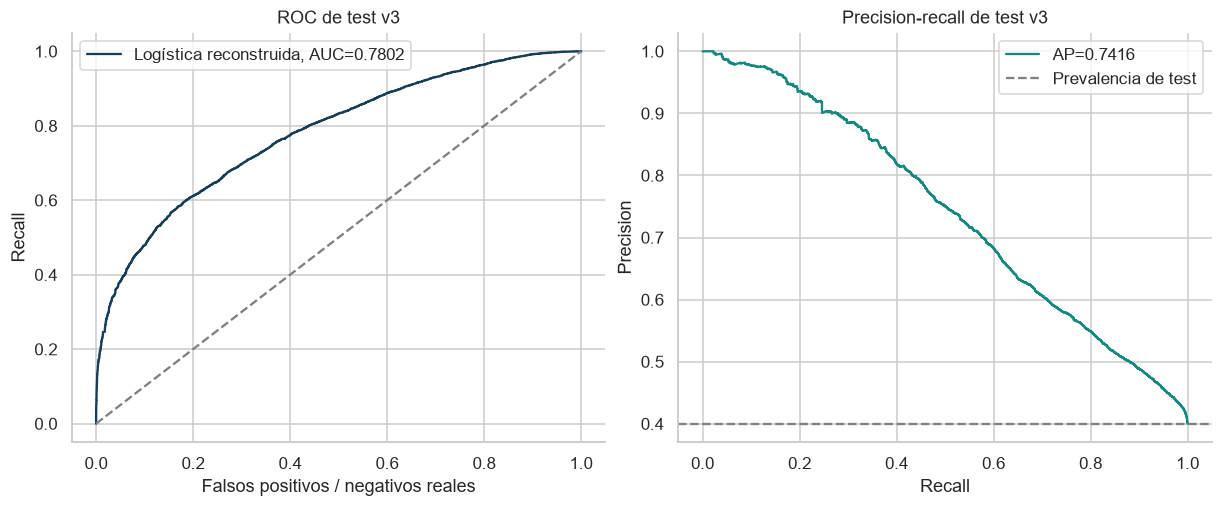

In [12]:
fig,ax=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
fpr,tpr,_=roc_curve(y.loc[te],p_test)
pr,rc,_=precision_recall_curve(y.loc[te],p_test)
ax[0].plot(fpr,tpr,color='#173e58',label=f"Logística reconstruida, AUC={test_policy['roc_auc']:.4f}")
ax[0].plot([0,1],[0,1],'--',color='gray');ax[0].set(title='ROC de test v3',xlabel='Falsos positivos / negativos reales',ylabel='Recall');ax[0].legend()
ax[1].plot(rc,pr,color='#168880',label=f"AP={test_policy['average_precision']:.4f}")
ax[1].axhline(y.loc[te].mean(),ls='--',color='gray',label='Prevalencia de test')
ax[1].set(title='Precision-recall de test v3',xlabel='Recall',ylabel='Precision');ax[1].legend()
plt.show();plt.close(fig)

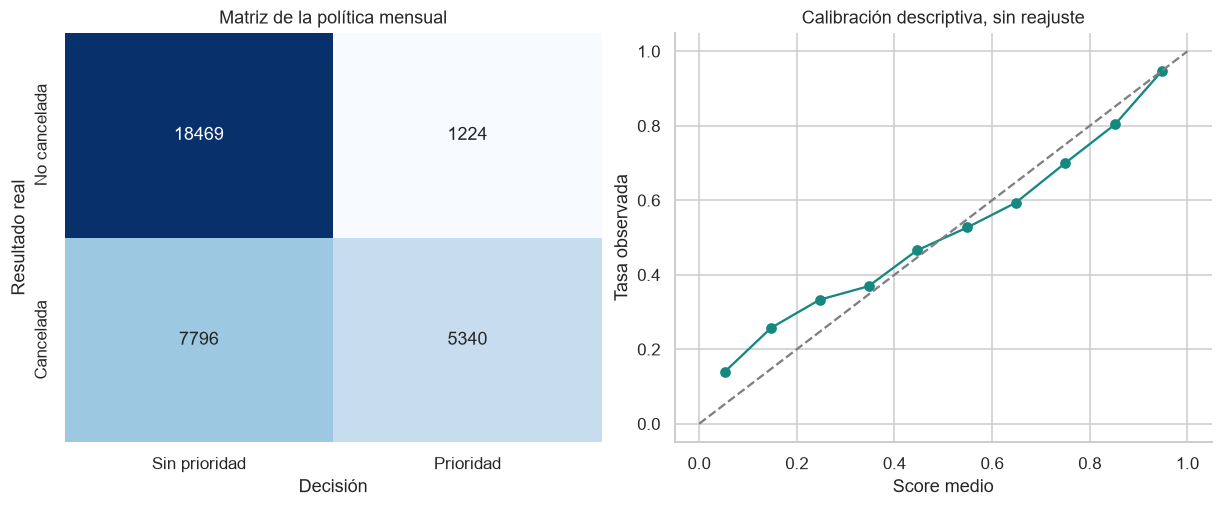

,dimensión,grupo,n,priorizadas,roc_auc,average_precision,precision,recall,f1,brier,tn,fp,fn,tp
0,hotel,City Hotel,22542,5349,0.788766,0.774550,0.829875,0.458764,0.590882,0.183007,11956,910,5237,4439
1,hotel,Resort Hotel,10287,1215,0.756181,0.635377,0.741564,0.260405,0.385455,0.190451,6513,314,2559,901
2,mes,2017-03,4970,994,0.802881,0.724756,0.803823,0.477871,0.599400,0.159612,3103,195,873,799
3,mes,2017-04,5661,1132,0.832910,0.821594,0.916961,0.421437,0.577469,0.165374,3104,94,1425,1038
4,mes,2017-05,6313,1262,0.821128,0.826062,0.938986,0.429037,0.588966,0.167203,3474,77,1577,1185
5,mes,2017-06,5647,1129,0.794315,0.781416,0.899911,0.416564,0.569507,0.181582,3095,113,1423,1016
6,mes,2017-07,5313,1062,0.712358,0.632814,0.681733,0.364919,0.475378,0.213248,2991,338,1260,724
7,mes,2017-08,4925,985,0.673913,0.545413,0.586802,0.318282,0.412710,0.231700,2702,407,1238,578


La cuota conjunta puede asignar distinto porcentaje de alertas a cada hotel. Las diferencias de temporada, canal y mezcla no prueban causalidad. Los scores no son probabilidades calibradas acreditadas; una curva descriptiva y Brier no autorizan un recalibrador sobre test.

In [13]:
matrix=np.array([[test_policy['tn'],test_policy['fp']],[test_policy['fn'],test_policy['tp']]])
fig,ax=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
sns.heatmap(matrix,annot=True,fmt='d',cbar=False,cmap='Blues',ax=ax[0],
            xticklabels=['Sin prioridad','Prioridad'],yticklabels=['No cancelada','Cancelada'])
ax[0].set(title='Matriz de la política mensual',xlabel='Decisión',ylabel='Resultado real')
bins=pd.cut(p_test,bins=np.linspace(0,1,11),include_lowest=True)
cal=pd.DataFrame({'score':p_test,'y':y.loc[te].to_numpy(),'bin':bins}).groupby('bin',observed=True).agg(
    n=('y','size'),score=('score','mean'),tasa=('y','mean'))
ax[1].plot(cal.score,cal.tasa,'o-',color='#168880');ax[1].plot([0,1],[0,1],'--',color='gray')
ax[1].set(title='Calibración descriptiva, sin reajuste',xlabel='Score medio',ylabel='Tasa observada')
plt.show();plt.close(fig)
detail=pd.DataFrame({'hotel':raw.loc[te,'hotel'].to_numpy(),'mes':test_decisions.mes.to_numpy(),
                     'y':y.loc[te].to_numpy(),'score':p_test,'alerta':test_decisions.alerta.to_numpy()})
segments=[]
for dim in ['hotel','mes']:
    for label,g in detail.groupby(dim):
        segments.append({'dimensión':dim,'grupo':label,'n':len(g),'priorizadas':int(g.alerta.sum()),
                         **metrics(g.y,g.score,g.alerta)})
segments=pd.DataFrame(segments);display(segments)
display(Markdown('La cuota conjunta puede asignar distinto porcentaje de alertas a cada hotel. Las diferencias '
 'de temporada, canal y mezcla no prueban causalidad. Los scores no son probabilidades calibradas acreditadas; '
 'una curva descriptiva y Brier no autorizan un recalibrador sobre test.'))

## 9. SHAP de la logística reconstruida

Modelo explicado: **regresión logística inicial reconstruida sobre 49.157 reservas de train v3**, C=1 y sin pesos. Se explica el clasificador después de su propio preprocesamiento: 192 columnas imputadas, escaladas y one-hot, con nombres obtenidos del transformador ajustado. No se reutiliza SHAP de XGBoost v2.

Referencia: muestra aleatoria fija de 500 filas exclusivamente de train; explicaciones: 1.000 filas aleatorias de validación. Usamos `LinearExplainer` con referencia independiente. Los SHAP se expresan en **log-odds**: base + contribuciones = margen de logística, y la sigmoide del margen = probabilidad. Se comprobará esa igualdad. La referencia independiente y el one-hot introducen supuestos; las contribuciones explican el modelo, no efectos causales ni intervenciones comerciales.

Los dos ejemplos se eligen por máximo y mínimo score de validación, antes de mirar sus etiquetas. Son extremos ilustrativos, no casos representativos ni ejemplos escogidos en test. 

**Leyenda del SHAP summary plot:** rojo indica un valor alto de la variable transformada; azul, un valor bajo. En una dummy one-hot, alto/bajo corresponde a 1/0. La posición horizontal indica si la contribución eleva (derecha, positiva) o reduce (izquierda, negativa) el margen respecto a la referencia. Por tanto, un punto rojo puede estar a la izquierda: rojo no significa por sí mismo mayor riesgo.

**Leyenda del SHAP waterfall:** rojo indica contribución positiva al margen del modelo y azul contribución negativa. En esta regresión logística, base, margen y SHAP se expresan en **log-odds**, la escala usada por el explicador. No son puntos porcentuales de probabilidad: hay que aplicar la sigmoide a la suma completa para obtener el score probabilístico; cada contribución no se convierte por separado en un cambio aditivo de probabilidad.

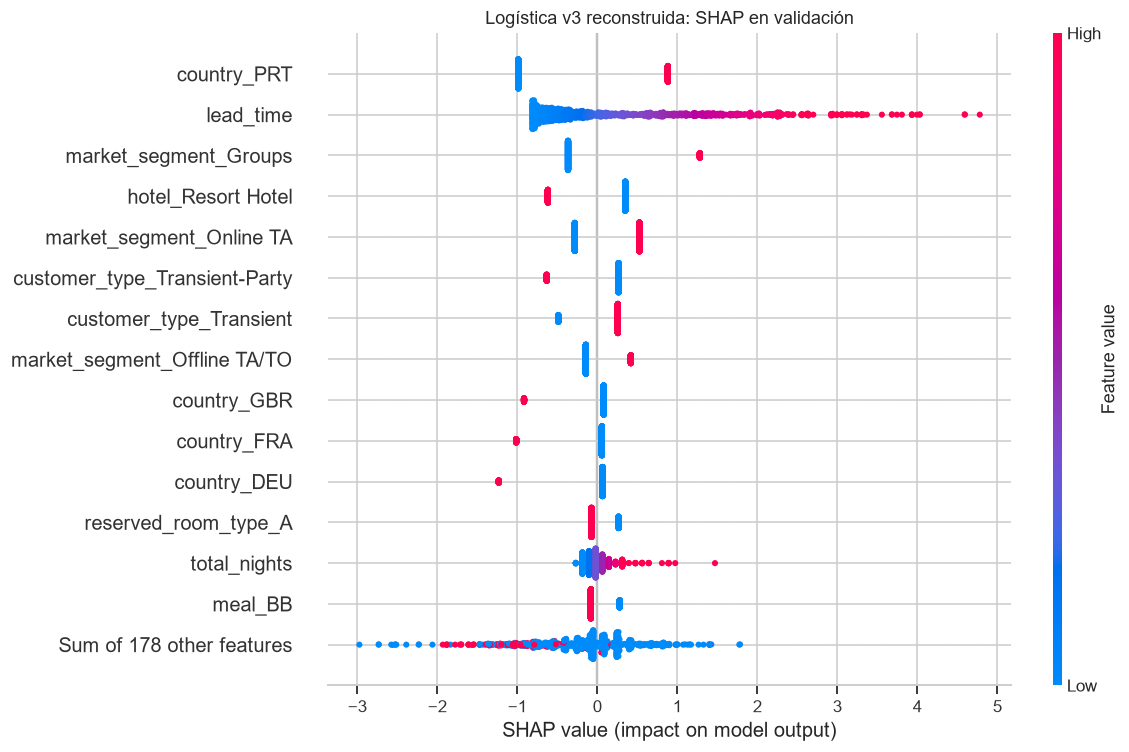

,variable_transformada,media_abs_SHAP
131,categorical__country_PRT,0.949912
0,numeric__lead_time,0.888342
169,categorical__market_segment_Groups,0.489459
7,categorical__hotel_Resort Hotel,0.432124
171,categorical__market_segment_Online TA,0.406015
191,categorical__customer_type_Transient-Party,0.330208
190,categorical__customer_type_Transient,0.299859
170,categorical__market_segment_Offline TA/TO,0.202366
73,categorical__country_GBR,0.169094
72,categorical__country_FRA,0.159082


In [14]:
pre=baseline.named_steps['preprocessor'];clf=baseline.named_steps['classifier']
names=pre.get_feature_names_out()
assert len(names)==192
bg_index=X.loc[tr].sample(n=500,random_state=SEED).index
sample_index=X.loc[va].sample(n=1000,random_state=SEED).index
vp=validation_scores['logística histórica reconstruida']
cases_index=[X.index[va][int(np.argmax(vp))],X.index[va][int(np.argmin(vp))]]
explain_index=pd.Index(list(dict.fromkeys(sample_index.tolist()+cases_index)))
background=pre.transform(X.loc[bg_index]).toarray()
transformed=pre.transform(X.loc[explain_index]).toarray()
explainer=shap.LinearExplainer(clf,shap.maskers.Independent(background,max_samples=500))
explanations=explainer(transformed)
plot_names=[n.replace("numeric__", "").replace("categorical__", "") for n in names]
explanations.feature_names=plot_names
margin=clf.decision_function(transformed)
shap_error=float(np.max(np.abs(explanations.base_values+explanations.values.sum(axis=1)-margin)))
np.testing.assert_allclose(explanations.base_values+explanations.values.sum(axis=1),margin,atol=1e-10,rtol=1e-10)
np.testing.assert_allclose(expit(margin),baseline.predict_proba(X.loc[explain_index])[:,1],atol=1e-12,rtol=1e-12)
assert not set(explain_index)&set(X.index[te]) and set(bg_index)<=set(X.index[tr])
shap.plots.beeswarm(explanations[:1000],max_display=15,show=False)
plt.gcf().set_size_inches(11,7);plt.title('Logística v3 reconstruida: SHAP en validación')
plt.tight_layout();plt.show();plt.close()
importance=pd.DataFrame({'variable_transformada':names,'media_abs_SHAP':np.abs(explanations.values[:1000]).mean(axis=0)}).sort_values('media_abs_SHAP',ascending=False)
display(importance.head(12))

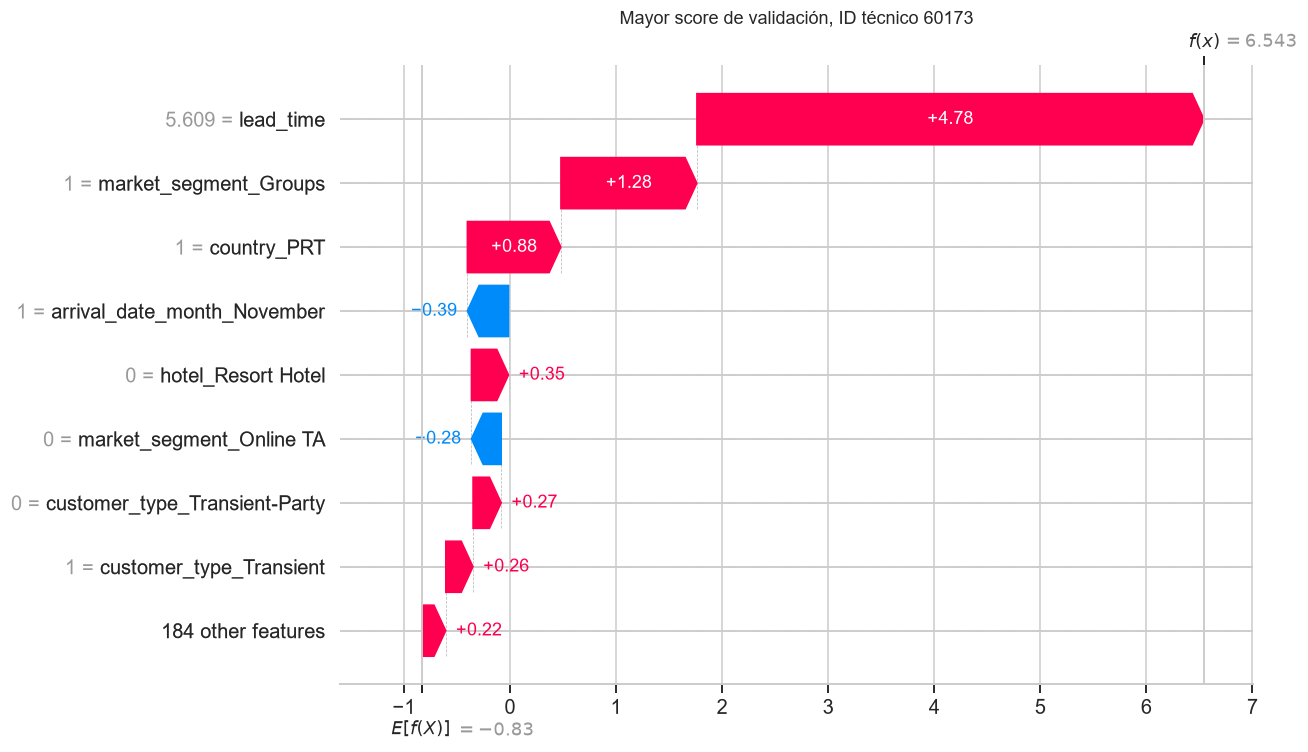

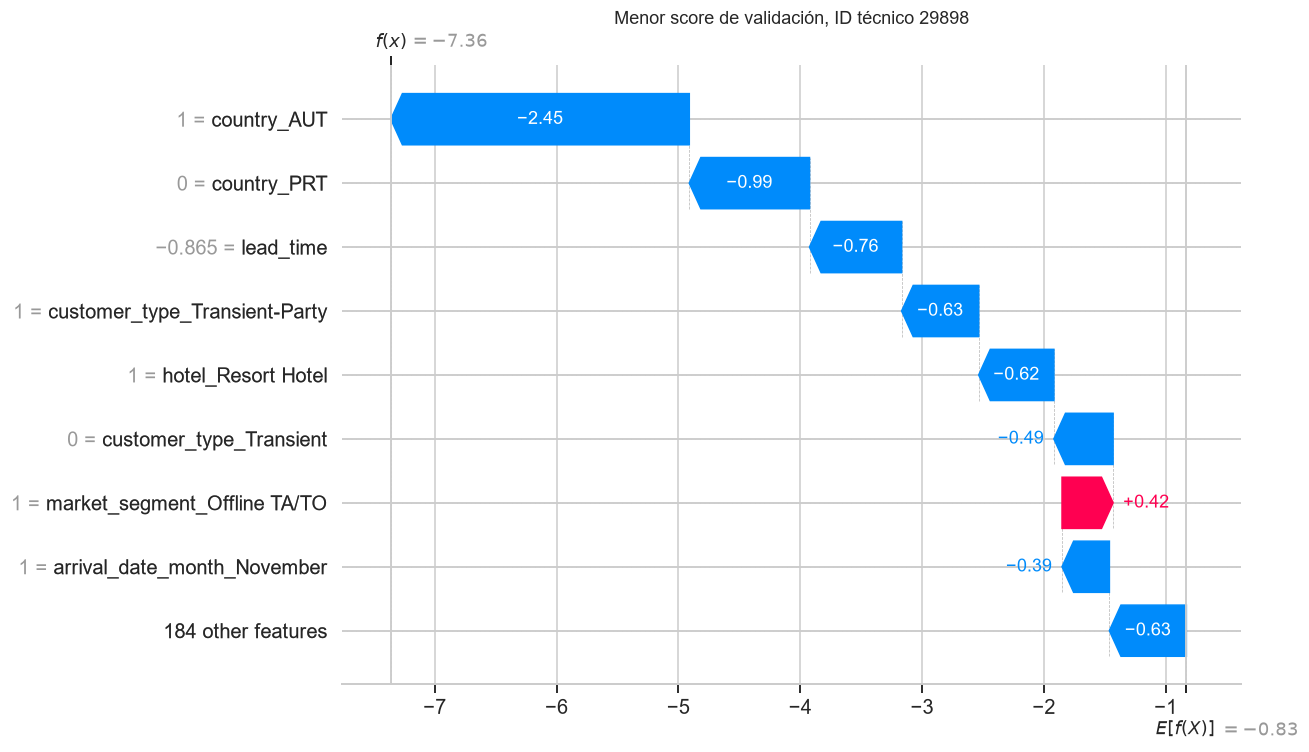

,ejemplo,id,score,base_log_odds,principales_contribuciones
0,Mayor score de validación,60173,0.998562,-0.830329,numeric__lead_time: +4.781; categorical__marke...
1,Menor score de validación,29898,0.000636,-0.830329,categorical__country_AUT: -2.450; categorical_...


In [15]:
case_rows=[]
for label,idx in zip(['Mayor score de validación','Menor score de validación'],cases_index):
    pos=explain_index.get_loc(idx)
    shap.plots.waterfall(explanations[pos],max_display=9,show=False)
    plt.gcf().set_size_inches(12,7);plt.title(f'{label}, ID técnico {idx}')
    plt.tight_layout();plt.show();plt.close()
    vpos=X.index[va].get_loc(idx)
    contributions=explanations.values[pos]; strongest=np.argsort(np.abs(contributions))[-3:][::-1]
    case_rows.append({'ejemplo':label,'id':int(idx),'score':float(vp[vpos]),
                     'base_log_odds':float(explanations.base_values[pos]),
                     'principales_contribuciones':'; '.join(f'{names[j]}: {contributions[j]:+.3f}' for j in strongest)})
display(pd.DataFrame(case_rows))

In [16]:
# Agregación descriptiva por predictor original: suma de dummies por fila y luego media absoluta.
groups={c:[i for i,n in enumerate(names) if n==f'numeric__{c}' or n.startswith(f'categorical__{c}_')] for c in FEATURES}
assert sorted(i for indices in groups.values() for i in indices)==list(range(len(names)))
group_values=np.column_stack([explanations.values[:1000,groups[c]].sum(axis=1) for c in FEATURES])
group_importance=pd.Series(np.abs(group_values).mean(axis=0),index=FEATURES).sort_values(ascending=False)
high_positions=np.argsort(vp)[-max(1,len(vp)//10):]
high=X.loc[va].iloc[high_positions]
display(pd.DataFrame({'mediana_validación':X.loc[va][NUM].median(),'mediana_decil_score_alto':high[NUM].median()}))
display(group_importance.rename('media_abs_suma_SHAP').to_frame())
display(Markdown('**Perfil de riesgo del modelo:** los predictores originales con más contribución agregada son **'
    + ', '.join(group_importance.head(3).index)+'**. El summary muestra la dirección por valor/dummy y los waterfall '
    'explican los dos casos concretos. Las medianas del decil alto describen composición, no reglas universales. '
    'Usar estas señales para priorizar revisión humana, nunca para penalizar nacionalidades o clientes automáticamente.'))

,mediana_validación,mediana_decil_score_alto
lead_time,66.0,308.0
total_nights,3.0,3.0
adults,2.0,2.0
children,0.0,0.0
babies,0.0,0.0
children_missing,0.0,0.0


,media_abs_suma_SHAP
country,1.293823e+00
lead_time,8.883423e-01
customer_type,6.326713e-01
hotel,5.222779e-01
market_segment,4.228345e-01
arrival_date_month,2.041972e-01
total_nights,1.259729e-01
distribution_channel,1.247152e-01
meal,6.008029e-02
adults,5.236040e-02


**Perfil de riesgo del modelo:** los predictores originales con más contribución agregada son **country, lead_time, customer_type**. El summary muestra la dirección por valor/dummy y los waterfall explican los dos casos concretos. Las medianas del decil alto describen composición, no reglas universales. Usar estas señales para priorizar revisión humana, nunca para penalizar nacionalidades o clientes automáticamente.

### Interpretación del perfil de mayor score (salidas de la celda 27)

Las tablas ya calculadas muestran una **mediana de lead_time de 308 días en el decil de mayor score frente a 66 en toda la validación**. No todas las características cambian: en ambos grupos las medianas son tres noches, dos adultos y cero niños/bebés, y la mediana del indicador de niños desconocidos es cero. Este contraste describe composición; no demuestra que aumentar la antelación cause cancelación ni que cada reserva anticipada vaya a cancelar.

La importancia SHAP agregada por predictor original destaca **country, lead_time y customer_type**. Esto mide magnitud, no dirección. En el summary, valores altos de antelación y la presencia de determinadas dummies, como `country_PRT` y `market_segment_Groups`, tienen contribuciones positivas al margen de este modelo respecto a la referencia. No se concluye que pertenecer a una categoría incremente necesariamente las cancelaciones por sí mismo: intervienen el resto de características, la población observada y los supuestos de explicación.

**Caso de mayor score, ID 60173:** score 0,998562, con contribuciones principales de antelación +4,781, Groups +1,282 y PRT +0,882 log-odds. Esas contribuciones elevan su margen respecto a la base −0,830329; no son incrementos porcentuales de probabilidad. **Caso de menor score, ID 29898:** score 0,000636; las mayores contribuciones reductoras son AUT −2,450, ausencia de PRT −0,987 y antelación −0,756 log-odds. Son los dos extremos de validación escogidos por score, no casos representativos ni certezas sobre su desenlace; los scores no tienen calibración acreditada.

**Implicación para Revenue Management:** usar el horizonte de reserva y el perfil conjunto como apoyo a una cola de revisión humana, dimensionando capacidad por hotel/mes y monitorizando cobertura y falsas alertas. Las reservas anticipadas pueden motivar una hipótesis de recordatorios o reconfirmación a evaluar en un piloto controlado. No cambiar automáticamente precio, depósito o trato al cliente por país/segmento ni atribuir ahorro o cancelaciones evitadas a estas asociaciones.

## 10. Limitaciones y uso empresarial

- Dos hoteles y poco más de dos años; duplicados conservados y sin IDs reales de cliente/grupo. No se acredita independencia de observaciones ni generalización a otros hoteles.
- Llegadas retrospectivas, snapshots inciertos, cierre de test supuesto y exposición previa de parte de test. La búsqueda complementaria es posterior y solo sirve de evidencia académica interna.
- Capacidad mensual hipotética compartida, lote completo y scores sin calibración acreditada. No hay costes reales ni estimación causal del seguimiento.
- La reconstrucción no reemplaza los artefactos originales. Coincidir en métricas no acredita por sí solo identidad de parámetros o scores; la validación técnica externa de la entrega documenta ese contraste.

**Propuesta:** presentar una cola de revisión humana limitada por capacidad, con monitorización mensual por hotel, canal, FN y cobertura. Para probar utilidad real, recopilar snapshots de creación, cierre/ingestión de etiquetas y capacidad/costes del hotel; después validar en reservas nuevas y realizar un piloto controlado. No adaptar decisiones con este test conocido.

In [17]:
execution_seconds=time.perf_counter()-INICIO
VALIDACION={'python':platform.python_version(),'versiones':VERSIONES,'csv_sha256':CSV_SHA,
    'filas':len(raw),'particiones':partition.value_counts().to_dict(),'folds':fold_rows,
    'ajustes_cv':len(audit_calls),'busqueda_segundos':search_seconds,'candidato_complementario':best_params,
    'cv':search_table.to_dict('records'),'comparación_validación':comparison.to_dict('records'),
    'política_validación':validation_policy.to_dict('records'),'test_nuevo':current,'test_umbral_05':test_fixed,
    'referencia_histórica':HISTORICAL,'max_diferencia_métricas_históricas':float(historical_comparison.diferencia.abs().max()),
    'n_inferencias_test_esta_ejecución':1,'candidato_nuevo_evaluado_test':False,
    'shap_error_aditividad':shap_error,'shap_train_referencia':len(bg_index),'shap_validación_muestra':1000,
    'n_features_transformadas':len(names),'casos_SHAP':case_rows,
    'importancia_original_SHAP':group_importance.to_dict(),'segmentos':segments.to_dict('records'),
    'tiempo_segundos_hasta_resumen':execution_seconds}
display(Markdown(f'**Comprobaciones:** 18 ajustes internos; SHAP aditivo (error máximo {shap_error:.2g}); '
    f'192 columnas transformadas; una inferencia de test solo de logística histórica reconstruida. '
    f'Tiempo observado hasta este resumen: {execution_seconds:.1f} s.'))

**Comprobaciones:** 18 ajustes internos; SHAP aditivo (error máximo 1.8e-15); 192 columnas transformadas; una inferencia de test solo de logística histórica reconstruida. Tiempo observado hasta este resumen: 6.1 s.

## Conclusiones finales accionables

1. **Priorizar seguimiento, con capacidad explícita.** La referencia histórica detectó 5.340 cancelaciones entre 6.564 prioridades (precision 81,35%; recall 40,65%; AUC 0,7802). La tabla anterior presenta las cifras de esta ejecución y sus diferencias; las referencias no sustituyen el cálculo nuevo.
2. **Atender las cancelaciones no cubiertas.** Históricamente quedaron 7.796 FN y hubo 1.224 FP. Revisar cobertura, carga de atención y diferencias por hotel antes de decidir recursos; no asumir ahorro ni cancelaciones evitadas.
3. **Conservar la decisión histórica.** La búsqueda posterior en train demuestra optimización y comparación de pesos; su ganador no reemplaza automáticamente la logística inicial ni se evalúa sobre test para escoger un resultado favorable.
4. **Usar SHAP como explicación del modelo.** Summary y dos waterfall pertenecen a logística reconstruida v3 y a validación, con referencia de train. Los factores son asociaciones modeladas, no causas ni motivos para trato adverso automático.
5. **Obtener evidencia operativa nueva.** Registrar snapshots, seguimiento, IDs y costes; realizar validación externa y un piloto humano con reservas nuevas. La ejecución técnica reproducible mantiene el alcance retrospectivo y la exposición previa declarados.